# <center>Ecuación de Lane-Emden</center>
----------------------------------------------------------


<center>
Juan Sebastian Calixto Pernett - Astrofísica Computacional
</center>


## 1. Introducción

El propósito del estudio de la estructura estelar consiste en caracterizar el estado interno de una estrella dentro de un equilibiro estacionario, definido por sus parámetros masa total $(M)$, radio $(R)$ y luminosidad $(L)$.

Para esto se busca obtener una descripción detallada de variables de estado como la densidad $(\rho)$, presión $(P)$ y temperatura $(T)$ a lo largo de la estructura. Una de las restricciones principales utilizadas será la omisión de la presión de radiación dentro del equilibrio hidrostático, junto con una composición química dominada por hidrógeno y helio.

## 2. Derivación de la ecuación de Lane-Emden

Partiendo del equilibrio hidrostático para una configuración de masa simétrica esféricamente, se tiene una presión de la forma:

\begin{equation}\tag{1}
    \frac{dP}{dr} = -\frac{GM(r)}{r^2}\rho
\end{equation}

Por otro lado, la conservación de la masa demanda

\begin{equation}\tag{2}
    \frac{dM(r)}{dr} = 4\pi r^2 \rho
\end{equation}

Asumiendo que el material estelar se comporta como un **gas ideal**:

\begin{equation}\tag{3}
    P = \frac{R_g}{\mu}\rho T
\end{equation}

En este caso tomamos un peso molecular medio $\mu$ **constante**.

Tomando una relación politrópica de la forma $P = K\rho^{1 + \frac{1}{n}}$, con $n$ el índice politrópico y $K$ una constante de proporcionalidad. Adicionalmente es posible introducir las variables adimensionales $\theta$ y $\xi$ como:

\begin{equation}\nonumber
    T = T_c \theta ~~~~~,~~~~~ r = \alpha \xi ~~~ con ~~~ \alpha = \sqrt{\frac{(n+1)K\rho_c ^{\frac{1}{n} - 1}}{4\pi G}}
\end{equation}

Obtenemos la expresión para la densidad:

\begin{equation}\tag{4}
    \rho = \rho_c \theta^n    
\end{equation}

Relacionando las expresiones (1) y (2), reemplazando la presión en función de $\theta$ y realizando un cambio de variable a $\xi$, es posible obtener la **ecuación de Lane-Emden**, para un "gas autogravitacional":

\begin{equation}\tag{5}
    \frac{1}{\xi ^2}  \frac{d}{d\xi}\left(\xi ^2 \frac{d\theta}{d\xi}\right) = -\theta ^n  
\end{equation}

La cual se encuentra sujeta a las condiciones de frontera relacionadas al estado central de la estrella:

\begin{equation}\tag{6}
    \theta(0) = 1 ~~~~~ y ~~~~~ \left.\frac{d\theta}{d\xi}\right|_{\xi=0} = 0
\end{equation}

Tres soluciones analíticas de interés son las respectivas a los índices politrópicos $n=0$ (densidad uniforme), $n=1$ (relación lineal) y $n=5$ (esfera de schuster).

### 2.1. Soluciones analíticas específicas

Para $n=0$ se obtiene una ecuación de segundo orden sencilla, cuya solución una vez incluidas las condiciones de frontera es:

\begin{equation}\nonumber
    \theta(\xi) = 1 - \frac{\xi ^2}{6}
\end{equation}

Para $n=1$ se obtiene una ecuación lineal esférica de Bessel de orden 0, cuya solución es de la forma:

\begin{equation}\nonumber
    \theta(\xi) = \frac{\sin \xi}{\xi}
\end{equation}

Finalmente, para $n=5$ es posible analizar una solución de la forma:

\begin{equation}\nonumber
    \theta(\xi) = \frac{1}{\sqrt{1 + \frac{\xi ^2}{3}}}
\end{equation}

Mientras que las primeras raíces positivas de $n = 0, 1$ se encuentran en $\xi = \sqrt{6}, \pi$ respectivamente, se observa que la solución de $n=5$ no tiene una raíz finita. Sin embargo es posible demostrar que esta expresión sigue implicando una masa finita, representando así un modelo de una fuente puntual altamente concentrada, como se podrá observar posteriormente.

## 3. Metodología Numérica

### 3.1 Integración numérica: Runge-Kutta 4

Para encontrar la solución del sistema para $\theta = \theta(\xi)$, tomamos las variables $y_0 = \theta$ y $y_1 = \theta' = {y_0}'$. De esta manera será posible definir un sistema de ecuaciones diferenciales ordinarias representanes de la ecuación de Lane-Emden:

\begin{align}
    \tag{7.1} \frac{dy_0}{d\xi} &= y_{1} \\[5pt]
    \tag{7.2} \frac{dy_1}{d\xi} &= -{y_{0}}^{n} - \frac{2}{\xi}y_1
\end{align}

Para resolver numéricamente este sistema, necesitaremos valores iniciales proporcionados por las condiciones de frontera para $\xi = 0$. Sin embargo, en la expresión (7.2) observamos una división entre $x$, lo cual causará inconsistencias en la ejecución del código.

Para resolver esto, tomamos un valor cercano al origen para reemplazar el valor inicial de $\xi$, denominado `xi_offset`. Con este valor calculamos los valores iniciales de las variables a integrar con una expansión de Taylor de la forma:

\begin{align*}
    \theta(\xi)  &\approx 1 -\frac{1}{6}\xi^2 + \frac{n}{120}\xi^4 \\[7pt]
    \theta'(\xi) &\approx   -\frac{1}{3}\xi   + \frac{n}{30}\xi^4
\end{align*}

Con esto será posible comenzar la integración por RK4.

### 3.2 Verificación por diferencias finitas

Una vez obtenido el conjunto de datos pertinente a la solución del sistema de ecuaciones diferenciales ordinarias, será posible realizar una verificación sistemática de los gradientes $\theta' = y_1$ obtenidos durante el proceso.

Para esto escogemos una cierta cantidad de puntos `N_midpoints` sobre los cuales realizar un proceso de diferenciación numérica utilizando los datos obtenidos de $\theta = y_0$, con el objetivo de calcular el error entre este valor y aquel obtenido por medio de RK4.

### 3.3 Búsqueda de raíces

Parte del objetivo detrás de la solución de la ecuación de Lane-Emden es la determinación de lo que llamaríamos una **superficie estelar**, cuya distancia respecto al centro, $\xi_1$, definiremos como la primera raíz positiva de la temperatura adimensional.

\begin{align*}
    \theta(\xi_1) = 0
\end{align*}

Para esto, el principal parámetro detrás de la finalización del ciclo de integración RK4 es la existencia de un cambio de signo en el valor de $y_0$, lo cual representaría que la curva atravesó el origen, y por lo tanto existe una raíz finita la cual encontrar. 

Escogiendo un cierto subconjunto de valores alrededor del último punto o rango de integración $[\xi_{i-1}, \xi_{i}]$ (en donde se presenta el cambio de signo), será posible encontrar un polinomio de interpolación por medio del método de **Newton de Diferencias Divididas**.

Posteriormente se realizará un proceso de búsqueda de raíces (**Bisección** o **Newton-Raphson**) sobre el polinomio de interpolación calculado, para así encontrar la superficie estelar.

## 4. Código principal

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
from IPython.display import display, Markdown

In [111]:
# Constantes físicas:

G = 6.674e-8 # cm^3 g^-1 s^-2 
M = 1.989e33 # g
R = 6.957e10 # cm

# Densidad media:

rho_m = 3*M / (4*np.pi * R**3) 

# Parámetros de solución:

h = 0.1
xi_offset = 1e-5

In [112]:
# -------------------------------------------------
# INTEGRACIÓN NUMÉRICA (ODEs): MÉTODO RUNGE-KUTTA 4
# -------------------------------------------------

# Singularidad de theta(xi) cerca al origen:

# Para tratar con la singularidad de 2/xi en el origen, tomaremos un valor desplazado para xi inicial en vez de cero (un "offset").
# El valor de la función (y1) y su derivada (y2) en este offset se calcula mediante la expansión de Taylor proporcionada.

def theta0_taylor(x, n):
    return 1 - x**2 / 6 + n * x**4/120    

def theta0_taylor_dot(x, n):
    return -x/3 + n * x**3 / 30

# Sistema de ecuaciones: Definiendo theta = y0, theta' = y1

# [y0'] = [f0(x, y0, y1)] = [y1              ]
# [y1']   [f1(x, y0, y1)]   [-y0^n - (2/xi)y1]

def f(x, y):

    # Como parte del proceso de integración, tendremos un valor negativo de theta(xi) al final del arreglo de soluciones
    # Como resultado, es posible tener problemas al calcular las n-potencias de estos valores negativos, por lo cual tomamos
    # el mayor valor entre estos y 0 para calcular el paso de integración.
    theta = max(0, y[0])
    f0 = y[1]
    f1 = -(theta**n) - (2/x)*y[1]

    return np.array([f0, f1])

# Paso runge kutta de 4to orden:

def rk4_step(x_i, y_i, h, f):

    k1 = f(x_i, y_i)
    k2 = f(x_i + h/2, y_i + k1*h/2)
    k3 = f(x_i + h/2, y_i + k2*h/2)
    k4 = f(x_i + h, y_i + k3*h)

    return y_i + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

# Implementación iterativa:

def rk4(f, x_start, y_start, h, max_steps=1e4):

    # Crear arreglos. El arreglo y_arr tiene la información de y0 y y1.
    x_arr = [x_start]
    y_arr = [y_start]

    # La primera condición de integración es que el último valor calculado ([-1]) sea mayor a 0, cuando deje de cumplirse esta condición
    # será porque theta habrá cruzado el eje y = 0, y por lo tanto tendremos una raíz para calcular la superficie estelar, punto en el cual
    # paramos de integrar.

    # Por otro lado, para índices politrópicos mayores o iguales a 5, la curva de theta(xi) nunca cruzará el eje horizontal, por lo que esta condición
    # no será suficiente, razón por la cual se incluye un máximo número de iteraciones.
    while (y_arr[-1][0] > 0) and (len(x_arr) < max_steps):
        y_next = rk4_step(x_arr[-1], y_arr[-1], h, f)
        x_next = x_arr[-1] + h

        y_arr.append(y_next)
        x_arr.append(x_next)

    y_arr = np.array(y_arr)
    x_arr = np.array(x_arr)

    return x_arr, y_arr    

# -------------------------------------
# VERIFICACIÓN POR DIFERENCIAS FINITAS:
# -------------------------------------

# Para realizar la verificación de los gradientes (y1) calculados, tomaremos un número N de puntos dentro del intervalo, sin incluir los puntos de los extremos.
# En cada uno de estos puntos, identificado por un cierto percentil del conjunto de datos de xi, calcularemos la derivada numérica por diferencias finitas centrales.
# Y calcularemos el error relativo porcentual para cada uno de ellos.

def finitediff_verification(x, y, h, N):
    # En este caso, calculamos el porcentaje correspiente a cada punto con un arreglo entre 0 y 1.
    midpoints_percent = np.linspace(0, 1, N+2)
    # Con len(x), calculamos los índices correspondienes a cada porcentaje (aunque lo aproximamos a un entero para tomar un valor correspondiente del arreglo de solución).
    midpoints_index = np.array([int(percent*len(x)) for percent in midpoints_percent])
    # Excluimos los extremos
    midpoints_index = midpoints_index[1:-1]

    x_verification = np.empty(N)
    ydot_verification = np.empty(N)
    diff_centered = np.empty(N)

    # Diferencias finitas centradas:
    for i in range(N):
        diff_centered[i] = (y[midpoints_index[i] + 1, 0] - y[midpoints_index[i] - 1, 0]) / (2*h)
        ydot_verification[i] = y[midpoints_index[i], 1]
        x_verification[i] = x[midpoints_index[i]]

    eps = abs( (diff_centered - ydot_verification)/diff_centered ) * 100

    return x_verification, ydot_verification, diff_centered, eps

# ------------------------------------
# INTERPOLACIÓN (DIVIDED DIFFERENCES):
# ------------------------------------

# Se buscará interpolar un intervalo cercano al cambio de signo de la variable y1 = theta(xi), pues en este lugar se encontrará la raíz.
def divided_differences(x, y):
    n = len(x)
    matrix = np.zeros((n, n))

    for i in range(n):
        matrix[i][0] = y[i]

    for j in range(1, n):
        for i in range(0, n-j):
            matrix[i][j] = (matrix[i+1][j-1] - matrix[i][j-1]) / (x[i+j] - x[i])

    coef = matrix[0][:]

    return coef

def newton_interp(x, coef, x_eval):
    n = len(coef)
    result = coef[n-1]
    result_dot = 0 

    # Para cálculos posteriores necesitaremos tanto el valor del polinomio como de su derivada, la cual puede calcularse directamente:
    for i in range(n-2, -1, -1):
        result_dot = result + result_dot*(x_eval - x[i])
        result = result*(x_eval - x[i]) + coef[i]

    return result, result_dot

# -------------------
# BÚSQUEDA DE RAÍCES:
# -------------------

def bisection(x_start, x, coef, pol, m, max_iter=1e5, text=False):

    scarborough = 0.5 * 10**(2-m)
    eps = 100
    counter = 0

    xl, xu = x_start[0], x_start[-1] 
    fl = pol(x, coef, xl)[0]
    fu = pol(x, coef, xu)[0]

    if fl * fu < 0:
        xm_former = None

        while (eps > scarborough):
            xm_current = (xl + xu)/2
            fm = pol(x, coef, xm_current)[0]
            counter +=1

            if xm_former is not None:
                eps = abs( (xm_former - xm_current)/xm_current ) * 100

            if fl * fm < 0:
                xu = xm_current
                fu = fm
            else:
                xl = xm_current
                fl = fm

            xm_former = xm_current

            if (counter >= max_iter) and text:
                print("Se alcanzó el máximo de iteraciones.")
                break

        x_root = xm_current
        # Obtenemos tanto la raíz como el valor de la derivada en ese punto.
        y_root, ydot_root = pol(x, coef, x_root)

    else: 
        x_root, y_root, ydot_root = np.nan, np.nan, np.nan
        if text:
            print("El intervalo inicial no incluye la raíz.")

    return x_root, y_root, ydot_root, counter


# Es posible utilizar el método de Newton_Raphson, sin embargo decidí no utilizarlo para agilizar el tratamiento de los casos 
# en los cuales la curva no cuenta con una raíz (como para n >= 5).
def newton_raphson(x0, x, coef, pol, m, max_iter=1e3, text=False):

    # Definimos un criterio de parada para la búsqueda de la raíz
    scarborough = 0.5 * 10**(2-m)
    eps = 100
    x_current = x0
    counter = 0

    # Una vez calculado el polinomio de interpolación, nuestro objetivo es hallar sus raíces por medio del método Newton-Raphson,
    # para lo cual también necesitamos la derivada del polinomio (como se mencionó antes)
    while eps > scarborough:
        f_current, fdot_current = pol(x, coef, x_current)

        if fdot_current == 0:
            print("Derivada nula (división por cero) en la búsqueda de Newton-Raphson")
            break

        # Se calcula la nueva raíz estimada
        x_next = x_current - f_current/fdot_current

        # Si x_next llega a ser igual a 0 (aunque no sucede en este caso), aproximamos el error por el error absoluto y no relativo.
        if x_next == 0:
            eps = 100 * abs(x_next - x_current) 
        else:
            eps = 100 * abs((x_next - x_current)/x_next)
        
        x_current = x_next
        counter += 1

        if (counter >= max_iter) and text:
            print("Se ha alcanzado el máximo número de iteraciones en la búsqueda.")
            break

    # Obtenemos tanto la raíz como el valor de la derivada en ese punto.
    x_root = x_current
    y_root, ydot_root = pol(x, coef, x_root)

    return x_root, y_root, ydot_root, counter


## Comparación con resultados analíticos conocidos (n = 0, 1, 5)

A modo de comparación y verificación cualitativa, se grafican los resultados del proceso de integración para los valores del índice politrópico 0, 1 y 5. 

**Tabla de verificación ($n = 0$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 0.40001 |              -0.133337 |                         -0.133337 |         2.49794e-13 |
| 0.80001 |              -0.26667  |                         -0.26667  |         0           |
| 1.30001 |              -0.433337 |                         -0.433337 |         0           |
| 1.70001 |              -0.56667  |                         -0.56667  |         0           |
| 2.10001 |              -0.700003 |                         -0.700003 |         3.17205e-14 |

**Tabla de verificación ($n = 1$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 0.50001 |              -0.16254  |                         -0.162379 |           0.0993094 |
| 1.10001 |              -0.324177 |                         -0.323861 |           0.0975833 |
| 1.60001 |              -0.408709 |                         -0.408323 |           0.0945371 |
| 2.20001 |              -0.434545 |                         -0.434162 |           0.0882398 |
| 2.70001 |              -0.393466 |                         -0.393154 |           0.079193  |

**Tabla de verificación ($n = 5$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 1.60001 |             -0.211381  |                        -0.211249  |           0.0629079 |
| 3.30001 |             -0.110412  |                        -0.110449  |           0.0331063 |
| 5.00001 |             -0.0584509 |                        -0.0584662 |           0.0261446 |
| 6.60001 |             -0.0359818 |                        -0.0359883 |           0.0180168 |
| 8.30001 |             -0.0235849 |                        -0.0235879 |           0.0124584 |

**Tabla de errores respecto a la solución analítica:**

|   $n$ |   $\epsilon_{max}$ $(\%)$ |   $\epsilon_{min}$ $(\%)$ |
|------:|--------------------------:|--------------------------:|
|     0 |               2.6307e-12  |               0           |
|     1 |               0.0496725   |               1.11022e-14 |
|     5 |               0.000278071 |               0           |

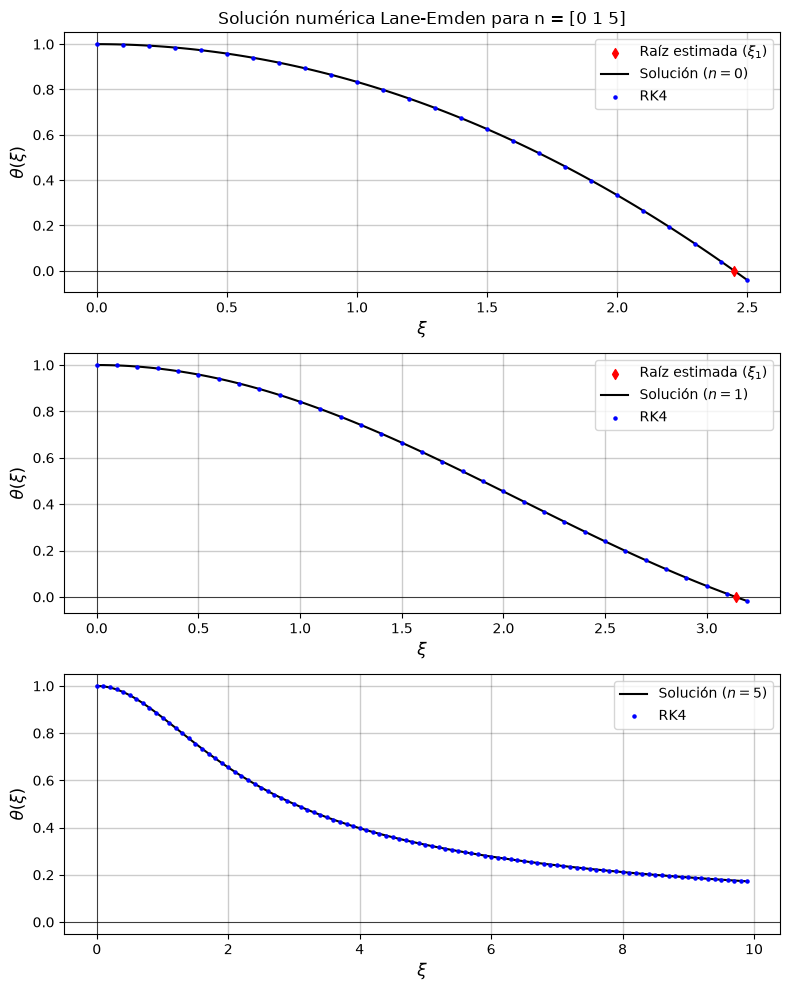

In [113]:
# --------------------------------------
# COMPARACIÓN CON RESULTADOS ANALÍTICOS CONOCIDOS:
# --------------------------------------

# Soluciones analíticas para comparación preliminar del código:

# Se definen las soluciones analíticas conocidas dependiendo del valor de n
def theta_n(x, n):
    # Para n=0 (densidad uniforme):
    if n == 0:
        return 1 - x**2 / 6
    # Para n=1 (relación lineal):
    elif n == 1:
        return np.sin(x)/x
    # Para n=5 (esfera de Schuster):
    elif n == 5:
        return 1/np.sqrt(1 + x**2 / 3)

# Parámetros y valores iniciales

n_comp = np.array([0, 1, 5])

fig, ax = plt.subplots(3, 1, figsize=(8,10), sharex=False, gridspec_kw={'height_ratios': [1, 1, 1]})

analytic_comp = []

for i, n in enumerate(n_comp):

    verification_comp = []

    y_starting = np.array([theta0_taylor(xi_offset, n), theta0_taylor_dot(xi_offset, n)])
    x_start = xi_offset

    # Solución numérica:

    x_num, y_num = rk4(f, x_start, y_starting, h, max_steps=1e2)

    # Solución analítica:

    x_analytic = np.linspace(x_start, x_num[-1], 100)
    y_exac_n = theta_n(x_analytic, n)

    # Verificación por diferencias finitas:

    N_midpoints = 5

    x_ver, ydot_ver, diff_centered, eps_ver = finitediff_verification(x_num, y_num, h, N_midpoints)

    for j in range(N_midpoints):
        verification_comp.append({
            "$\\xi$" : x_ver[j],
            '$\\theta\'(\\xi)$ [RK4]' : ydot_ver[j],
            '$\\theta\'(\\xi)$ [Diff. Centered]' : diff_centered[j],
            '$\\epsilon$ $(\\%)$' : eps_ver[j]
        })

    df_comp = f"**Tabla de verificación ($n = {n}$):**\n\n" + pd.DataFrame(verification_comp).to_markdown(index=False)

    display(Markdown(df_comp))

    # Interpolación:

    coef_num = divided_differences(x_num[-4:], y_num[-4:, 0])

    # Búsqueda de raíces:

    m = 5

    xi_root, theta_root, thetadot_root, counter = bisection(x_start=x_num[-3:], x=x_num[-4:], coef=coef_num, pol=newton_interp, m=m)

    # Sólo graficar raíces para aquellas curvas que tengan:
    if y_num[-1, 0] <= 0:
        ax[i].scatter(xi_root, theta_root, color='r', s=25, marker='d', label='Raíz estimada ($\\xi_1$)', zorder=6)

    # Comparación con datos analíticos:

    y_exac_comp = theta_n(x_num, n)
    err_rel = np.abs( (y_num[:, 0] - y_exac_comp)/y_exac_comp ) * 100

    err_rel_max = max(err_rel)
    err_rel_min = min(err_rel)

    analytic_comp.append({
            "$n$" : n,
            '$\\epsilon_{max}$ $(\\%)$' : err_rel_max,
            '$\\epsilon_{min}$ $(\\%)$' : err_rel_min,
    })

    # Gráfica para comparar con resultados analíticos n = 0, 1, 5:

    ax[i].plot(x_analytic, y_exac_n, color='k', linewidth=1.5, label=f'Solución ($n={n}$)')
    ax[i].scatter(x_num, y_num[:, 0], color='b', s=5, marker='o', label='RK4', zorder=5)
    ax[i].axhline(y=0, color='k', linewidth=0.5, alpha=1)
    ax[i].axvline(x=0, color='k', linewidth=0.5, alpha=1)
    ax[i].set_xlabel('$\\xi$', fontsize=12)
    ax[i].set_ylabel('$\\theta(\\xi)$', fontsize=12)
    ax[i].legend()
    ax[i].grid(color='k', linewidth=1, alpha=0.2)

df_err = f"**Tabla de errores respecto a la solución analítica:**\n\n" + pd.DataFrame(analytic_comp).to_markdown(index=False)

display(Markdown(df_err))

ax[0].set_title(f'Solución numérica Lane-Emden para n = {n_comp}', fontsize=12)

plt.tight_layout()
plt.show()


## Solución para índices politrópicos solicitados

**Tabla de verificación ($n = 3.0$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 1.70001 |             -0.276399  |                        -0.276173  |           0.0818256 |
| 3.50001 |             -0.148845  |                        -0.14889   |           0.0299604 |
| 5.20001 |             -0.0742915 |                        -0.0743151 |           0.0316761 |

**Tabla de verificación ($n = 3.15$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 1.90001 |             -0.260036  |                        -0.259896  |           0.053915  |
| 3.80001 |             -0.126695  |                        -0.126736  |           0.0329576 |
| 5.70001 |             -0.0606486 |                        -0.0606654 |           0.0278036 |

**Tabla de verificación ($n = 3.3$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 2.10001 |             -0.23997   |                        -0.239899  |           0.0297307 |
| 4.20001 |             -0.104064  |                        -0.104099  |           0.0335077 |
| 6.30001 |             -0.0487307 |                        -0.0487422 |           0.0236298 |

**Tabla de verificación ($n = 3.45$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 2.30001 |             -0.218458  |                        -0.218436  |           0.01009   |
| 4.60001 |             -0.0863379 |                        -0.0863655 |           0.0319726 |
| 6.90001 |             -0.0398972 |                        -0.0399052 |           0.0200714 |

**Tabla de verificación ($n = 3.6$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 2.60001 |             -0.189625  |                        -0.189644  |          0.00998266 |
| 5.20001 |             -0.0673829 |                        -0.0674021 |          0.0284699  |
| 7.80001 |             -0.0307063 |                        -0.0307112 |          0.016017   |

**Tabla de verificación ($n = 3.75$):**

|   $\xi$ |   $\theta'(\xi)$ [RK4] |   $\theta'(\xi)$ [Diff. Centered] |   $\epsilon$ $(\%)$ |
|--------:|-----------------------:|----------------------------------:|--------------------:|
| 2.90001 |             -0.163021  |                        -0.163058  |           0.0222986 |
| 5.90001 |             -0.0519918 |                        -0.0520044 |           0.0241172 |
| 8.80001 |             -0.0237495 |                        -0.0237525 |           0.0127078 |

**Tabla de parámetros para valores de $n = [3.0, 3.15, 3.3, 3.45, 3.6, 3.75]$:**

|   $n$ |   $\xi_1$ |   $\theta'_1$ |   $\rho_c / \rho_m$ |   $-\xi_1 ^2 \theta'_1$ |   $\omega_n ^0$ |   $N_n$ |   $W_n$ |   $P_c \ (10^{17} \text{ dyn/cm}^2)$ |
|------:|----------:|--------------:|--------------------:|------------------------:|----------------:|--------:|--------:|-------------------------------------:|
|  3    |    6.8969 |       -0.0424 |             54.1819 |                  2.0183 |          2.0183 |  0.3639 | 0.00488 |                            0.0005505 |
|  3.15 |    7.5319 |       -0.0348 |             72.0771 |                  1.976  |          1.7164 |  0.3722 | 0.00491 |                            0.0005535 |
|  3.3  |    8.285  |       -0.0282 |             97.8535 |                  1.9373 |          1.4703 |  0.3828 | 0.00493 |                            0.0005558 |
|  3.45 |    9.1915 |       -0.0225 |            136.11   |                  1.9017 |          1.2653 |  0.396  | 0.00494 |                            0.0005573 |
|  3.6  |   10.3016 |       -0.0176 |            194.951  |                  1.8693 |          1.0912 |  0.4123 | 0.00495 |                            0.000558  |
|  3.75 |   11.6903 |       -0.0135 |            289.455  |                  1.8398 |          0.9409 |  0.4323 | 0.00495 |                            0.0005579 |

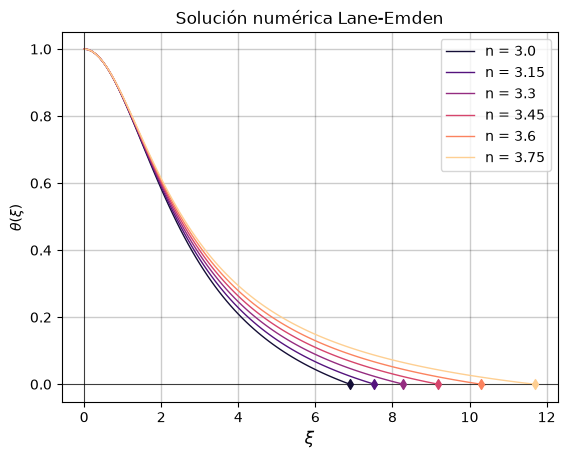

In [114]:
indices_n = [3.00, 3.15, 3.30, 3.45, 3.60, 3.75]
resultados_ode = {}
resultados_tabla = []

colors = cm.magma(np.linspace(0.1, 0.9, len(indices_n)))
plt.figure()

for i, n in enumerate(indices_n):
    color = colors[i]
    verification_tabla = []

    theta0     = 1 - xi_offset**2 / 6 + n * xi_offset**4 / 120
    theta0_dot = - xi_offset/3 + n * xi_offset**3 / 30
    y_start = np.array([theta0, theta0_dot])
    x_start = xi_offset

    # SOLUCIÓN:
    x_num, y_num = rk4(f, x_start, y_start, h)  

    plt.plot(x_num, y_num[:, 0], color=color, linewidth=1, label=f'n = {n}')

    # RAÍCES Y PARÁMETROS:

    coef_num = divided_differences(x_num[-4:], y_num[-4:, 0])
    m = 5
    xi_1, theta_1, thetadot_1, counter = bisection(x_start=x_num[-3:], x=x_num[-4:], coef=coef_num, pol=newton_interp, m=m)

    # Para valores de n en los cuales no se obtenga una raíz física, no se grafica y los valores asociados no están definidos.
    if y_num[-1, 0] <= 0:
        plt.scatter(xi_1, theta_1, color=color, s=25, marker='d', zorder=5)  
    else:
        print(f"Raíz no encontrada para n = {n}.")

    # VERIFICACIÓN DE GRADIENTES:

    N_midpoints = 3

    x_ver, ydot_ver, diff_centered, eps_ver = finitediff_verification(x_num, y_num, h, N_midpoints)

    for j in range(N_midpoints):
        verification_tabla.append({
            "$\\xi$" : x_ver[j],
            "$\\theta\'(\\xi)$ [RK4]" : ydot_ver[j],
            "$\\theta\'(\\xi)$ [Diff. Centered]" : diff_centered[j],
            '$\\epsilon$ $(\\%)$' : eps_ver[j]
        })

    df_comp = f"**Tabla de verificación ($n = {n}$):**\n\n" + pd.DataFrame(verification_tabla).to_markdown(index=False)
    display(Markdown(df_comp))

    # DENSIDADES:

    rho_ratio = -xi_1 / (3 * thetadot_1)

    rho_c = rho_ratio * rho_m

    # CONSTANTES ADIMENSIONALES:

    mass_param = -(xi_1**2) * thetadot_1

    omega_n0 = - xi_1**((n+1)/(n-1)) * thetadot_1

    N_n = ((4*np.pi / omega_n0**(n-1))**(1/n)) / (n+1)

    W_n = 1/(4*np.pi*(n+1)*(mass_param)**2)  

    # PRESIÓN CENTRAL:

    P_c = (W_n * G * (M**2) / (R**4)) / (10**17)

    # Analizando las unidades de medida de las constantes en P_c:
    # [P_c] = (cm^3 * g^-1 * s^-2) * g^2 * cm^-4 
    # [P_c] = g * cm^-1 * s^-2 = g * cm * cm^-2 * s^-2 = (g * cm * s^-2) * cm^-2
    # Siendo que 1 dyn = 1 g * cm / s^2
    # [P_c] = dyn / cm^2
    # Sólo es necesario dividir entre 10^17

    # Almacenar los resulados en un diccionario para uso posterior
    resultados_ode[n] = {
        'x' : x_num,
        'y' : y_num,
        'xi_1' : xi_1,
        'theta_1' : theta_1,
        'rho_c' : rho_c
    }

    # Añadir resultados a una tabla que imprimir
    resultados_tabla.append({
        "$n$": round(n, 2),
        "$\\xi_1$": round(xi_1, 4),
        "$\\theta'_1$": round(thetadot_1, 4),
        "$\\rho_c / \\rho_m$": round(rho_ratio, 4),
        "$-\\xi_1 ^2 \\theta'_1$": round(mass_param, 4),
        "$\\omega_n ^0$" : round(omega_n0, 4),
        "$N_n$" : round(N_n, 4),
        "$W_n$": round(W_n, 5),
        "$P_c \\ (10^{17} \\text{ dyn/cm}^2)$": round(P_c, 7),
    })   

df_tabla = f"**Tabla de parámetros para valores de $n = {indices_n}$:**\n\n" + pd.DataFrame(resultados_tabla).to_markdown(index=False)

display(Markdown(df_tabla))

plt.axhline(y=0, color='k', linewidth=0.5, alpha=1)
plt.axvline(x=0, color='k', linewidth=0.5, alpha=1)
plt.xlabel('$\\xi$', fontsize=12)
plt.ylabel('$\\theta(\\xi)$')
plt.title('Solución numérica Lane-Emden', fontsize=12)
plt.legend()
plt.grid(color='k', linewidth=1, alpha=0.2)

plt.show()

## Análisis comparativo

Desde los parámetros adimensionales $\theta$ y $\xi$:

\begin{align*}
    R = \alpha \xi
\end{align*}

Siendo $\alpha$ una constante dependiente del índice politrópico $n$. Para el sol, se tiene que el radio característico $\xi_1$ ocurre en:

\begin{align*}
    R_{\odot} = \alpha \xi_1  ~~~ \xrightarrow{} ~~~ \alpha = \frac{R_\odot}{\xi_1}
\end{align*}

De esta forma podemos normalizar la coordenada radial estelar $r$ como

\begin{align*}
    R = \left(\frac{R_\odot}{\xi_1}\right)\xi ~~~ \xrightarrow{} ~~~ \frac{R}{R_\odot} = \frac{\xi}{\xi_1}
\end{align*}

Por otro lado, sabemos que la densidad es de la forma: 

\begin{align*}
    \rho = \rho_c \theta^n
\end{align*}

Con $\theta = \theta(\xi)$, podemos obtener una serie de datos de $\rho$ en función de $\xi$ normalizado con $\xi / \xi_1$ (equivalente a $R/R_\odot$).

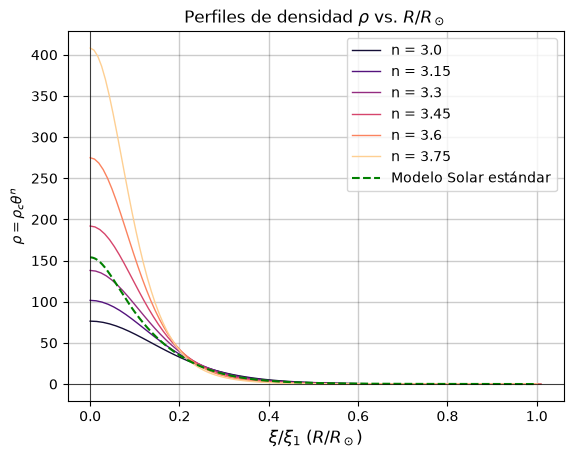

In [115]:
# Definimos la densidad en función de theta y n

def rho(y, rho_c, n):
    theta = np.maximum(0, y)
    return rho_c * theta**n

# Datos solares:

solar_data = np.loadtxt('solar_model.txt', comments='#')[::-1]
r_solar = solar_data[:, 0]
rho_solar = solar_data[:, 2]

# Gráficación para cada valor de n

plt.figure()
for i, n in enumerate(indices_n):
    color = colors[i]

    r_num = resultados_ode[n]['x']/resultados_ode[n]['xi_1']
    theta = resultados_ode[n]['y'][:, 0]
    rho_c = resultados_ode[n]['rho_c']

    rho_n = rho(theta, rho_c, n)

    plt.plot(r_num, rho_n, color=color, linewidth=1, label=f'n = {n}')

plt.plot(r_solar, rho_solar, color='g', linestyle='--', linewidth=1.5, label='Modelo Solar estándar')

plt.axhline(y=0, color='k', linewidth=0.5, alpha=1)
plt.axvline(x=0, color='k', linewidth=0.5, alpha=1)
plt.xlabel('$\\xi / \\xi_1$ $(R / R_\\odot)$', fontsize=12)
plt.ylabel('$\\rho = \\rho_c \\theta^n$')
plt.title('Perfiles de densidad $\\rho$ vs. $R/R_\\odot$', fontsize=12)
plt.legend()
plt.grid(color='k', linewidth=1, alpha=0.2)

plt.show()

Para alinear los datos numéricos con los puntos de `solar_model.txt`, interpolamos $\rho_{num}$ para posteriormente evualuar el polinomio resultante en los datos de `r_solar` de la base de datos.

Con este objetivo, para cada dato $r_i$ en `r_solar` se encuentra el intervalo [$x_{i-1}, x_i$] en `r_num` que contenga a $r_i$, para interpolar un valor de densidad que pase por ese valor, efectivamente calculando los valores de densidad numérica en los puntos de `r_solar`.

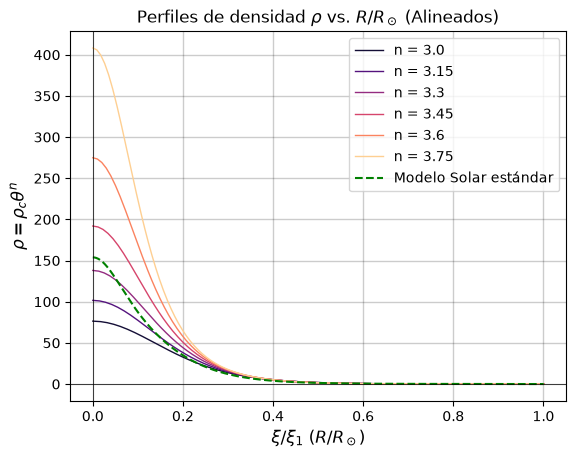

In [116]:
resultados_rho_interp = {}

def interp_lin(x_new, x, y):
        # Crear intervalos de interpolación.
        i = np.searchsorted(x, x_new)
        i = np.clip(i, 1, len(x) - 1)

        x0, x1 = x[i-1], x[i]
        y0, y1 = y[i-1], y[i]

        # Interpolar una cierta cantidad de puntos alrededor de cada valor en la grilla r_solar.
        y_new = y0 + (x_new - x0) * (y1 - y0) / (x1 - x0)

        y_new = np.where(x_new < x[0], y[0], y_new)
        y_new = np.where(x_new > x[-1], y[-1], y_new)

        return y_new

for i, n in enumerate(indices_n):
    color = colors[i]

    # Calcular los datos numéricos normalizados.
    r_num = resultados_ode[n]['x']/resultados_ode[n]['xi_1']
    rho_num = rho(resultados_ode[n]['y'][:,0], resultados_ode[n]['rho_c'], n=3)

    # Pasar estos datos por la interpolación para ser alineados con la grilla de los datos estándar.
    rho_num_alineada = interp_lin(r_solar, r_num, rho_num)
    err_abs = np.abs(rho_num_alineada - rho_solar)
    eps = np.abs((rho_num_alineada - rho_solar)/rho_solar) * 100

    # Agregar resultados a un diccionario.
    resultados_rho_interp[n] = {
        'rho_alineada' : rho_num_alineada,
        'error_abs' : err_abs,
        'eps' : eps
    }

    # Graficar datos numéricos alineados (ahora tendrán la misma longitud y valores de x que los datos estándar).
    plt.plot(r_solar, rho_num_alineada, color=color, linewidth=1, label=f'n = {n}')

plt.plot(r_solar, rho_solar, color='g', linestyle='--', linewidth=1.5, label='Modelo Solar estándar')

plt.axhline(y=0, color='k', linewidth=0.5, alpha=1)
plt.axvline(x=0, color='k', linewidth=0.5, alpha=1)
plt.xlabel('$\\xi / \\xi_1$ $(R/R_\\odot)$', fontsize=12)
plt.ylabel('$\\rho = \\rho_c \\theta^n$', fontsize=12)
plt.title('Perfiles de densidad $\\rho$ vs. $R/R_\\odot$ (Alineados)', fontsize=12)
plt.legend()
plt.grid(color='k', linewidth=1, alpha=0.2)

plt.show()

El máximo error absoluto entre el modelo politrópico de n = 3 y el modelo solar estandar es de 77.494 g/cm^3, con un error relativo del 50.365 %,
encontrado en r_solar = 0.0013911.

Por otro lado, el mínimo error absoluto es de 1.937e-12 g/cm^3, correspondiente al 0.007 % en r_solar = 1.0003829.


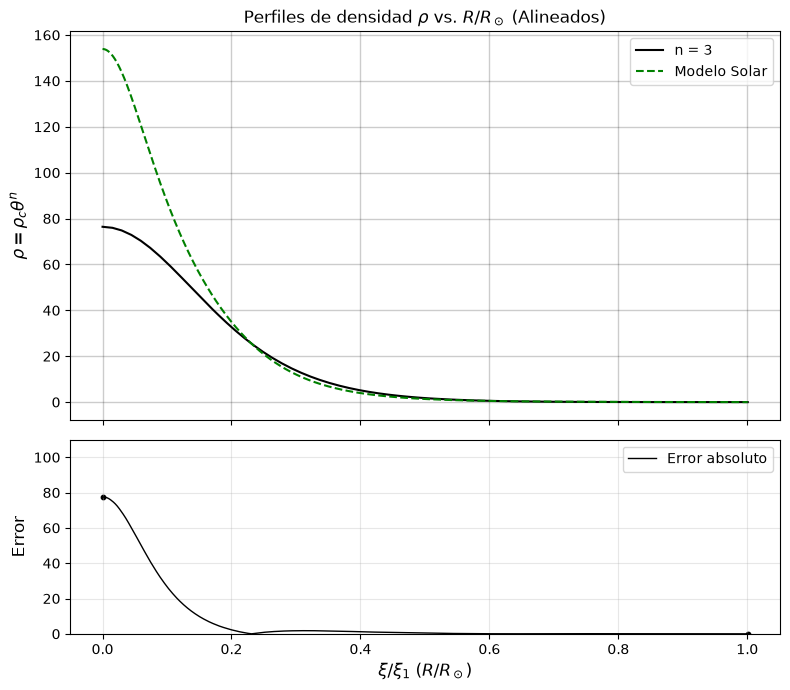

In [117]:
# Para el caso específico de n = 3 aislado:

n = 3

# Calcular el máximo y mínimo error (absoluto y relativo) entre ambos conjuntos de datos
idx_errmax = np.argmax(resultados_rho_interp[3]['error_abs'])
err_max_abs = resultados_rho_interp[3]['error_abs'][idx_errmax]
err_max_rel = resultados_rho_interp[3]['eps'][idx_errmax]

idx_errmin = np.argmin(resultados_rho_interp[3]['error_abs'])
err_min_abs = resultados_rho_interp[3]['error_abs'][idx_errmin]
err_min_rel = resultados_rho_interp[3]['eps'][idx_errmin]

print(f"El máximo error absoluto entre el modelo politrópico de n = {n} y el modelo solar estandar es de {err_max_abs:.3f} g/cm^3, con un error relativo del {err_max_rel:.3f} %,")
print(f"encontrado en r_solar = {r_solar[idx_errmax]}.")

print(f"\nPor otro lado, el mínimo error absoluto es de {err_min_abs:.3e} g/cm^3, correspondiente al {err_min_rel:.3f} % en r_solar = {r_solar[idx_errmin]}.")

# Graficar ambas curvas, junto con el error absoluto
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8,7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(r_solar, resultados_rho_interp[n]['rho_alineada'], 'k-', label=f'n = {n}')
ax1.plot(r_solar, rho_solar, color='g', linestyle='--', linewidth=1.5, label='Modelo Solar')
ax1.set_ylabel('$\\rho = \\rho_c \\theta^n$', fontsize=12)
ax1.set_title('Perfiles de densidad $\\rho$ vs. $R/R_\\odot$ (Alineados)', fontsize=12)
ax1.grid(color='k', linewidth=1, alpha=0.2)
ax1.legend()

# No se grafica el error relativo puesto que cerca a la superficie los valores de R/R_sun son extremadamente bajos, resultando en errores relativos extremadamente elevados.
# ax2.plot(r_solar, resultados_rho_interp[n]['eps'], 'k-', linewidth=1, label='Error relativo (%)')
ax2.plot(r_solar, resultados_rho_interp[n]['error_abs'], 'k-', linewidth=1, label='Error absoluto')
ax2.scatter(r_solar[idx_errmax], err_max_abs, color='k', s=10)
ax2.scatter(r_solar[idx_errmin], err_min_abs, color='k', s=10)
ax2.set_xlabel('$\\xi / \\xi_1$ $(R/R_\\odot)$', fontsize=12)
ax2.set_ylabel('Error', fontsize=12)
ax2.set_ylim(0, 110)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

Como es posible observar, el modelo politrópico para un índice de $n = 3$ subestima la densidad estelar en el centro del Sol, con un error absoluto máximo de alrededor de $77.5$ $g/cm^{3}$ y un error relativo porcentual del $50.4$\% aproximadamente, representando una discrepancia considerable.

Durante el desarrollo teórico previo a la solución de la ecuación de Lane-Emden se toma en cuenta una serie de suposiciones o aproximaciones con el objetivo de simplificar la resolución del problema. 

Dentro de estas se incluye la suposición de un peso molecular medio $\mu$ constante a lo largo de la estructura estelar. Sin embargo, dentro de la región central del sol (aproximadamente menor a $0.2$ veces $R_\odot$) se llevan a cabo varios procesos de fusión nuclear que transforman hidrógeno en helio, aumentando el peso molecular medio. Como es posible observar en el desarrollo teórico,

\begin{align*}
    P \propto \frac{1}{\mu}
\end{align*}

Por lo tanto, al aumentar el peso molecular medio la presión interna disminuye, resultando en una compresión del centro estelar mayor a la calculada por medio del modelo politrópico.

Otras aproximaciones realizadas incluyen un comportamiento de gas ideal, con cambios de naturaleza quasi-estática e índice politrópico $n$ constante a lo largo de la estructura, sin considerar los posibles mecanismos de generación energética en las distintas capas o regiones de la estrella. 

Analizando los valores de la tabla de comparación, es posible observar que $(d\theta/d\xi)|_{\xi_1}$ (la pendiente tangente a la curva $\theta(\xi)$ en $\xi_1$) disminuye en magnitud cerca a la superficie al aumentar el valor de $n$. Para el valor más bajo del conjunto ($n=3$) la pendiente es de $-0.04$ aproximadamente, aumentando hasta llegar a un valor estimado de $-0.01$ para $n=3.75$. En otras palabras, el gradiente de la densidad se vuelve más "suave" (la densidad varía de manera menos abrupta) para mayores índices politrópicos conforme nos acercamos a la superficie estelar.

Similarmente, la concentración central de densidad $\rho_c / \rho_m$ también aumenta con el índice politrópico, yendo de aproximadamente $54.2$ en $n=3$ hasta $289.5$ para $n =3.75$. Esto significa que, para estrellas de mayor índice politrópico, una mayor parte de su masa se encuentra concentrada en su centro en comparación con su densidad media, hecho que es posible observar también en las gráficas realizadas.